<a href="https://colab.research.google.com/github/gozdekorkut/double-descent-reproduction/blob/main/notebooks/05_make_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 — Final figures and paper-vs-ours tables

This notebook trains nothing. It reads the result CSVs written by notebooks 01–04 and produces:

1. the final figures for the report and the slides (readable axes, paper's key values marked for comparison),
2. one **overview figure** showing double descent in three model families side by side,
3. a **paper-vs-ours table** for each experiment (mean ± std over seeds), saved as CSV and as LaTeX to paste into the report.

Missing results are skipped, so the notebook can be run now and again when notebook 02 finishes.

**Paper values** are read from the paper's figures (Belkin et al. 2019, Fig. 2–5) and are therefore approximate (marked "≈"). Exact values are those printed as axis tick labels in the paper (e.g. 88 %, 447, 62 in Fig. 2).

**No GPU needed.** Runtime: CPU, under a minute.

## 1. Settings

- `MODE = "drive"`: reads from the shared `double-descent` folder on Google Drive and writes figures/tables back to it. Use this if you have the shared folder (or its shortcut) in your Drive.
- `MODE = "upload"`: you upload the CSV files by hand (a file picker appears in section 2); outputs are zipped and downloaded at the end. Use this if you cannot reach the shared folder.

In [1]:
MODE = "drive"        # "drive" or "upload"

DRIVE_DIR = "/content/drive/MyDrive/double-descent"
FILES = {
    "rff":         "rff_mnist_full.csv",
    "rff_kernel":  "rff_kernel_mnist_full.csv",
    "mlp_reuse":   "mlp_mnist_full_reuse.csv",
    "mlp_noreuse": "mlp_mnist_full_noreuse.csv",
    "relu":        "relu_1d_norms.csv",
    "forest":      "forest_mnist_full.csv",
}

## 2. Load whatever results exist

In [2]:
import os, glob, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

if MODE == "drive":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
    IN_DIR = f"{DRIVE_DIR}/results"
    OUT_DIR = f"{DRIVE_DIR}/figures/final"
else:
    from google.colab import files
    IN_DIR = "/content/uploaded_results"
    OUT_DIR = "/content/final"
    os.makedirs(IN_DIR, exist_ok=True)
    print("Select the CSV files from the 'results' folder (several at once is fine):")
    for name, data in files.upload().items():
        with open(f"{IN_DIR}/{name}", "wb") as f:
            f.write(data)
os.makedirs(OUT_DIR, exist_ok=True)

R = {}
for key, fname in FILES.items():
    path = f"{IN_DIR}/{fname}"
    if os.path.exists(path):
        R[key] = pd.read_csv(path)
        print(f"found    {fname:30s} {len(R[key]):4d} rows")
    else:
        print(f"MISSING  {fname}")

def save(fig, name):
    for ext in ["pdf", "png"]:
        fig.savefig(f"{OUT_DIR}/{name}.{ext}", dpi=200, bbox_inches="tight")

def pm(series, digits=2):
    # "mean ± std" over seeds
    s = pd.Series(series, dtype=float)
    return f"{s.mean():.{digits}f} ± {(s.std() if len(s) > 1 else 0):.{digits}f}"

def log_ticks(ax, ticks, axis="y"):
    # readable log-scale ticks, e.g. [2, 4, 8, 16, 32, 64]
    a = ax.yaxis if axis == "y" else ax.xaxis
    a.set_major_locator(FixedLocator(ticks)); a.set_major_formatter(FixedFormatter([f"{t:g}" for t in ticks]))
    a.set_minor_locator(NullLocator())

def save_table(rows, name, caption):
    t = pd.DataFrame(rows, columns=["Quantity", "Paper (≈, from figure)", "Ours (mean ± std)"])
    t.to_csv(f"{OUT_DIR}/{name}.csv", index=False)
    body = "\n".join(" & ".join(str(c).replace("%", r"\%").replace("±", r"$\pm$").replace("≈", r"$\approx$").replace("→", r"$\to$").replace("∞", r"$\infty$").replace("÷", "/").replace("—", "--").replace("<", r"$<$")
                                for c in r) + r" \\" for r in t.values)
    latex = ("\\begin{table}[h]\n  \\centering\n  \\caption{" + caption + "}\n  \\begin{tabular}{lcc}\n    \\toprule\n"
             "    Quantity & Paper & Ours \\\\\n    \\midrule\n    " + body.replace("\n", "\n    ") +
             "\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n")
    with open(f"{OUT_DIR}/{name}.tex", "w") as f:
        f.write(latex)
    display(t)

Mounted at /content/drive
found    rff_mnist_full.csv               54 rows
found    rff_kernel_mnist_full.csv         3 rows
found    mlp_mnist_full_reuse.csv         42 rows
found    mlp_mnist_full_noreuse.csv       42 rows
found    relu_1d_norms.csv               140 rows
found    forest_mnist_full.csv            42 rows


## 3. Experiment 1 — Random Fourier features (paper Fig. 2)

Hollow diamonds mark the paper's values that appear as tick labels in its Fig. 2: test error 88 % and norm 447 at the threshold, kernel norm 62.

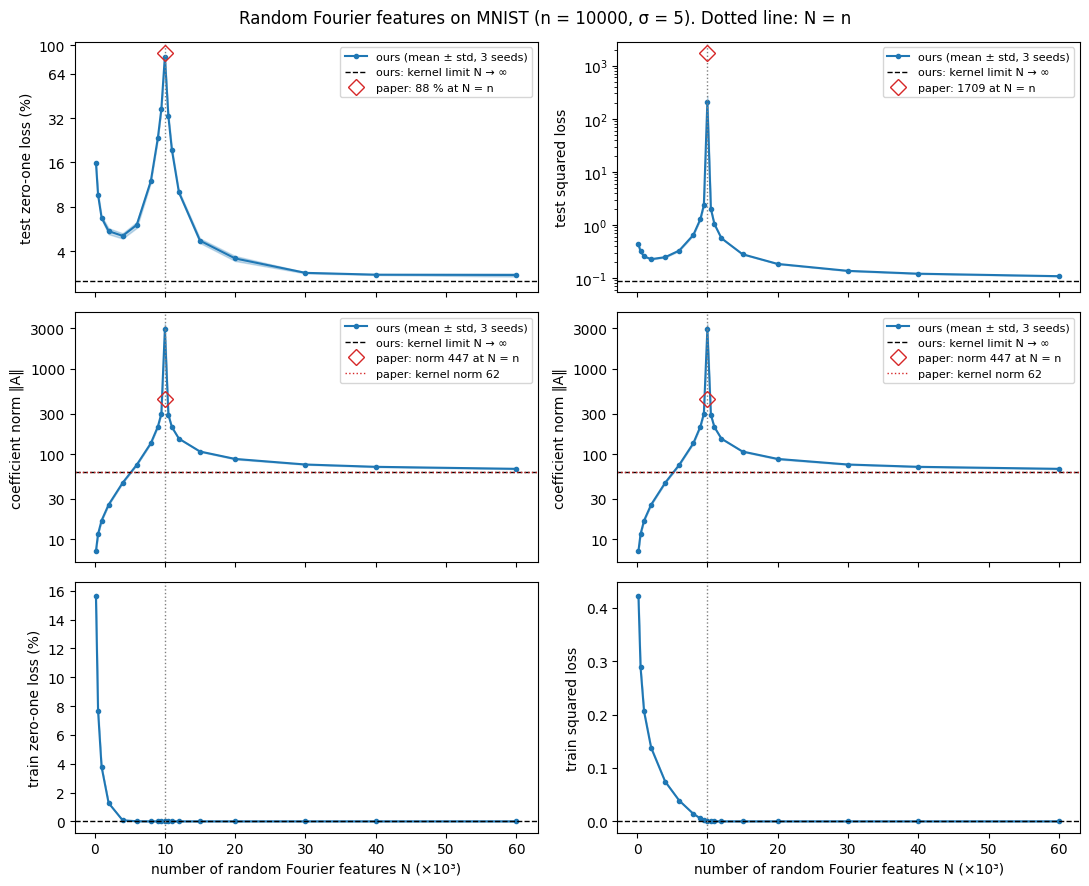

,Quantity,"Paper (≈, from figure)",Ours (mean ± std)
0,"Test error, smallest N (ours N = 200)",≈ 15 %,15.95 ± 0.22 %
1,"Train error, smallest N",≈ 14 %,15.62 ± 0.18 %
2,Best test error with N < n (ours N = 4000),≈ 4.5 %,5.09 ± 0.21 %
3,Test error at N = n = 10000,88 %,83.62 ± 1.09 %
4,Test squared loss at N = n,1709,209.6 ± 65.4
5,Norm at N = n,447,2922 ± 490
6,"Test error, largest N (ours N = 60000)",≈ 2.5 %,2.76 ± 0.07 %
7,"Test error, kernel limit (N → ∞)",≈ 2.2 %,2.52 ± 0.03 %
8,"Norm, kernel limit",62,61.2 ± 0.5


Claim check: peak at N = n? True.  Largest-N error 2.76 % below best classical 5.09 %? True


In [3]:
if "rff" in R:
    df, ker = R["rff"], R.get("rff_kernel")
    n = int(df.n.iloc[0]); g = df.groupby("N"); x = np.array(sorted(df.N.unique())) / 1000
    fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
    panels = [("test_err", "test zero-one loss (%)", "test_mse", "test squared loss"),
              ("norm", "coefficient norm ‖A‖", "norm", "coefficient norm ‖A‖"),
              ("train_err", "train zero-one loss (%)", "train_mse", "train squared loss")]
    for i, (c0, l0, c1, l1) in enumerate(panels):
        for j, (col, lab) in enumerate([(c0, l0), (c1, l1)]):
            ax = axes[i, j]
            m, s = g[col].mean().values, g[col].std().fillna(0).values
            ax.plot(x, m, "o-", ms=3, color="C0", label=f"ours (mean ± std, {df.seed.nunique()} seeds)")
            ax.fill_between(x, m - s, m + s, color="C0", alpha=0.25)
            if ker is not None and col in ker:
                ax.axhline(ker[col].mean(), color="k", ls="--", lw=1, label="ours: kernel limit N → ∞")
            ax.axvline(n / 1000, color="gray", ls=":", lw=1)
            ax.set_ylabel(lab)
    for j in range(2):
        axes[0, j].set_yscale("log"); axes[1, j].set_yscale("log")
        axes[2, j].set_xlabel("number of random Fourier features N (×10³)")
    log_ticks(axes[0, 0], [2, 4, 8, 16, 32, 64, 100])
    log_ticks(axes[1, 0], [10, 30, 100, 300, 1000, 3000]); log_ticks(axes[1, 1], [10, 30, 100, 300, 1000, 3000])
    axes[0, 0].plot(n / 1000, 88, "D", mfc="none", mec="C3", ms=8, label="paper: 88 % at N = n")
    for j in range(2):
        axes[1, j].plot(n / 1000, 447, "D", mfc="none", mec="C3", ms=8, label="paper: norm 447 at N = n")
        axes[1, j].axhline(62, color="C3", ls=":", lw=1, label="paper: kernel norm 62")
    axes[0, 1].plot(n / 1000, 1709, "D", mfc="none", mec="C3", ms=8, label="paper: 1709 at N = n")
    for ax in axes[:2].ravel():
        ax.legend(fontsize=8)
    fig.suptitle(f"Random Fourier features on MNIST (n = {n}, σ = 5). Dotted line: N = n")
    fig.tight_layout(); save(fig, "fig_rff_mnist"); plt.show()

    # ---- table ------------------------------------------------------------
    by_seed = {s: d.set_index("N") for s, d in df.groupby("seed")}
    under = sorted(N for N in df.N.unique() if N < n)
    best_N = df[df.N.isin(under)].groupby("N").test_err.mean().idxmin()
    Nmin, Nmax = df.N.min(), df.N.max()
    rows = [
        [f"Test error, smallest N (ours N = {Nmin})", "≈ 15 %", pm([d.loc[Nmin, "test_err"] for d in by_seed.values()]) + " %"],
        [f"Train error, smallest N", "≈ 14 %", pm([d.loc[Nmin, "train_err"] for d in by_seed.values()]) + " %"],
        [f"Best test error with N < n (ours N = {best_N})", "≈ 4.5 %", pm([d.loc[best_N, "test_err"] for d in by_seed.values()]) + " %"],
        [f"Test error at N = n = {n}", "88 %", pm([d.loc[n, "test_err"] for d in by_seed.values()]) + " %"],
        [f"Test squared loss at N = n", "1709", pm([d.loc[n, "test_mse"] for d in by_seed.values()], 1)],
        [f"Norm at N = n", "447", pm([d.loc[n, "norm"] for d in by_seed.values()], 0)],
        [f"Test error, largest N (ours N = {Nmax})", "≈ 2.5 %", pm([d.loc[Nmax, "test_err"] for d in by_seed.values()]) + " %"],
    ]
    if ker is not None:
        rows += [["Test error, kernel limit (N → ∞)", "≈ 2.2 %", pm(ker.test_err) + " %"],
                 ["Norm, kernel limit", "62", pm(ker.norm, 1)]]
    save_table(rows, "table_rff", "Random Fourier features on MNIST, $n = 10^4$ (paper Fig.~2). Paper values read from the figure.")
    best_classical = df[df.N == best_N].test_err.mean(); final = df[df.N == Nmax].test_err.mean()
    print(f"Claim check: peak at N = n? {df.groupby('N').test_err.mean().idxmax() == n}.  "
          f"Largest-N error {final:.2f} % below best classical {best_classical:.2f} %? {final < best_classical}")

## 4. Experiment 2 — Two-layer networks (paper Fig. 4 / 9)

Solid line: weight reuse below the threshold (paper Fig. 4 / 9a). Dashed: no weight reuse (Fig. 9c), if that run exists.
If the CSV has a `dead` column (dead hidden units after training), a second figure plots test error against the **effective** number of parameters, counting only alive units.

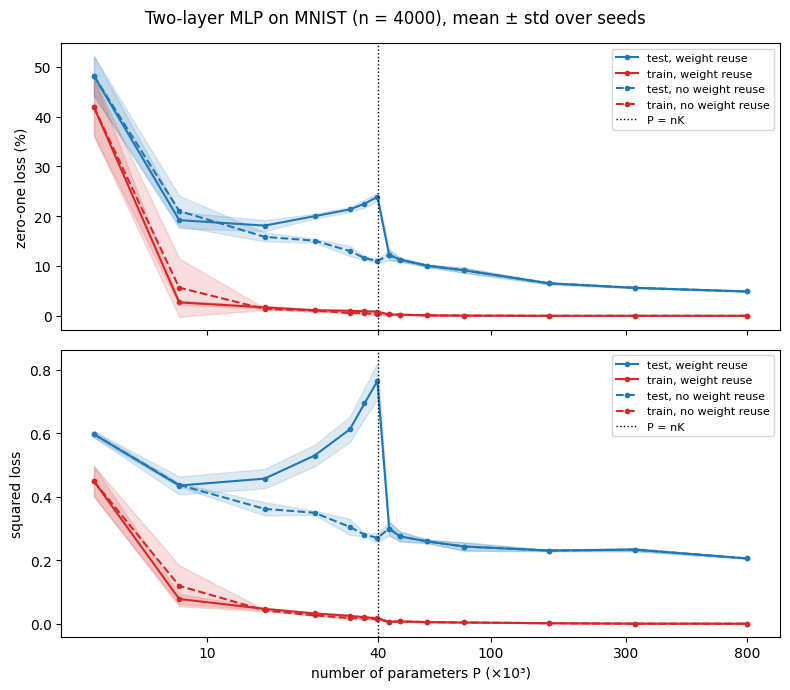

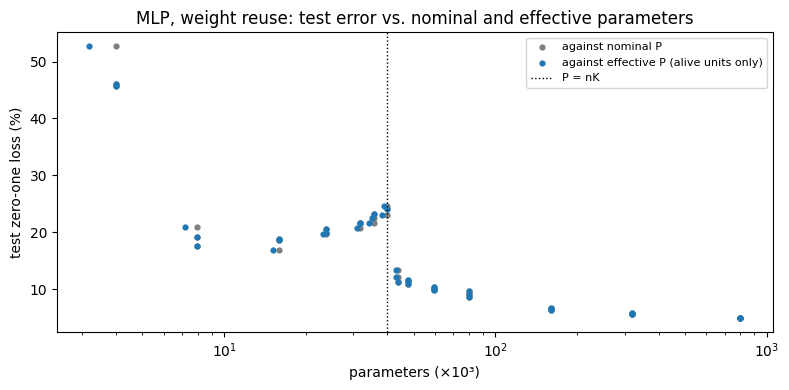

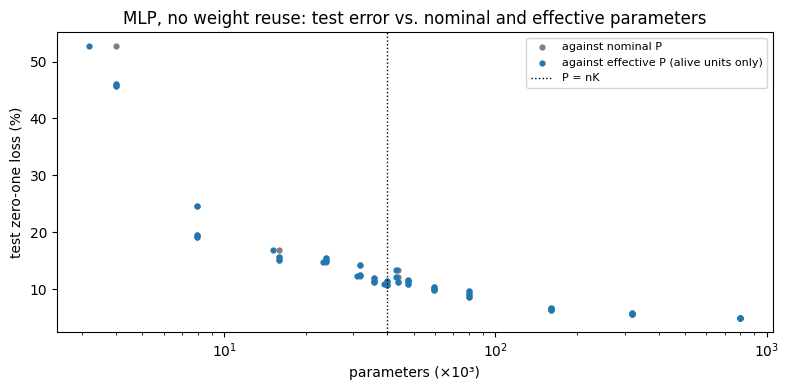

,Quantity,"Paper (≈, from figure)",Ours (mean ± std)
0,"Test error, smallest P (ours P = 3985)",≈ 56 %,48.17 ± 3.98 %
1,Best test error with P < nK (ours P = 15910),≈ 13 %,18.11 ± 1.11 %
2,Highest test error near P = nK (ours P = 39760),≈ 21 % (at P = nK),23.89 ± 0.80 %
3,Train error there,≈ 1 %,0.83 ± 0.28 %
4,Test squared loss there,≈ 0.55,0.765 ± 0.057
5,"Test error, largest P (ours P = 799780)",≈ 4.5 % (P ≈ 800k),4.88 ± 0.06 %
6,"Test squared loss, largest P",≈ 0.19,0.206 ± 0.001


In [4]:
mlp_runs = [(k, lab, ls) for k, lab, ls in [("mlp_reuse", "weight reuse", "-"), ("mlp_noreuse", "no weight reuse", "--")] if k in R]
if mlp_runs:
    n, K, D = int(R[mlp_runs[0][0]].n.iloc[0]), 10, 784
    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    for key, lab, ls in mlp_runs:
        g = R[key].groupby("P"); x = np.array(sorted(R[key].P.unique())) / 1000
        for ax, (te, tr) in zip(axes, [("test_err", "train_err"), ("test_mse", "train_mse")]):
            for col, color, what in [(te, "C0", "test"), (tr, "C3", "train")]:
                m, s = g[col].mean().values, g[col].std().fillna(0).values
                ax.plot(x, m, "o" + ls, ms=3, color=color, label=f"{what}, {lab}")
                ax.fill_between(x, m - s, m + s, color=color, alpha=0.15)
    for ax, lab in zip(axes, ["zero-one loss (%)", "squared loss"]):
        ax.axvline(n * K / 1000, color="k", ls=":", lw=1, label="P = nK")
        ax.set_ylabel(lab); ax.legend(fontsize=8)
    axes[1].set_xscale("log"); log_ticks(axes[1], [1, 3, 10, 40, 100, 300, 800], axis="x")
    axes[1].set_xlabel("number of parameters P (×10³)")
    fig.suptitle(f"Two-layer MLP on MNIST (n = {n}), mean ± std over seeds")
    fig.tight_layout(); save(fig, "fig_mlp_mnist"); plt.show()

    for key, lab, _ in mlp_runs:
        d = R[key]
        if "dead" in d:
            d = d.assign(alive=d.H - d.dead)
            d = d.assign(P_eff=(D + 1) * d.alive + (d.alive + 1) * K)
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.scatter(d.P / 1000, d.test_err, s=12, color="C7", label="against nominal P")
            ax.scatter(d.P_eff / 1000, d.test_err, s=12, color="C0", label="against effective P (alive units only)")
            ax.axvline(n * K / 1000, color="k", ls=":", lw=1, label="P = nK")
            ax.set_xscale("log"); ax.set_xlabel("parameters (×10³)"); ax.set_ylabel("test zero-one loss (%)")
            ax.set_title(f"MLP, {lab}: test error vs. nominal and effective parameters"); ax.legend(fontsize=8)
            fig.tight_layout(); save(fig, f"fig_mlp_effective_params_{key}"); plt.show()

    # ---- table (main run = first available) -------------------------------
    key, lab, _ = mlp_runs[0]; d = R[key]; per = d.groupby("P")
    under = d[d.P < n * K]; near = d[(d.P >= 0.5 * n * K) & (d.P <= 2 * n * K)]
    P_best = under.groupby("P").test_err.mean().idxmin() if len(under) else None
    P_peak = near.groupby("P").test_err.mean().idxmax() if len(near) else None
    Pmin, Pmax = d.P.min(), d.P.max()
    sel = lambda P, col: d[d.P == P][col]
    rows = [[f"Test error, smallest P (ours P = {Pmin})", "≈ 56 %", pm(sel(Pmin, "test_err")) + " %"]]
    if P_best is not None:
        rows.append([f"Best test error with P < nK (ours P = {P_best})", "≈ 13 %", pm(sel(P_best, "test_err")) + " %"])
    if P_peak is not None:
        rows += [[f"Highest test error near P = nK (ours P = {P_peak})", "≈ 21 % (at P = nK)", pm(sel(P_peak, "test_err")) + " %"],
                 [f"Train error there", "≈ 1 %", pm(sel(P_peak, "train_err")) + " %"],
                 [f"Test squared loss there", "≈ 0.55", pm(sel(P_peak, "test_mse"), 3)]]
    rows += [[f"Test error, largest P (ours P = {Pmax})", "≈ 4.5 % (P ≈ 800k)", pm(sel(Pmax, "test_err")) + " %"],
             [f"Test squared loss, largest P", "≈ 0.19", pm(sel(Pmax, "test_mse"), 3)]]
    save_table(rows, "table_mlp", f"Two-layer MLP on MNIST, $n = {n}$, {lab} (paper Fig.~4). Paper values read from the figure.")
else:
    print("No MLP results yet (notebook 02). Re-run this notebook when they exist.")

## 5. Experiment 3 — 1-D random ReLU features (paper Fig. 3)

The fitted curves themselves are already saved by notebook 03 (`figures/relu_1d_fits.png`). Here we only make the table.

In [5]:
if "relu" in R:
    d = R["relu"]
    s0 = d[d.seed == 0].set_index("N")
    med = d.groupby("N").norm.median()
    rows = [["Norm, N = 40 (feature seed 0, shown in figure)", "≈ 695", f"{s0.loc[40, 'norm']:.1f}"],
            ["Norm, N = 4000 (feature seed 0, shown in figure)", "≈ 159", f"{s0.loc[4000, 'norm']:.1f}"],
            ["Median norm over 20 seeds, N = 40", "—", f"{med.loc[40]:.1f}"],
            ["Median norm over 20 seeds, N = 4000", "—", f"{med.loc[4000]:.1f}"]]
    save_table(rows, "table_relu_1d", "1-D random ReLU features, $n = 10$ (paper Fig.~3). Our 10 data points differ from the paper's (not given).")

,Quantity,"Paper (≈, from figure)",Ours (mean ± std)
0,"Norm, N = 40 (feature seed 0, shown in figure)",≈ 695,236.7
1,"Norm, N = 4000 (feature seed 0, shown in figure)",≈ 159,162.5
2,"Median norm over 20 seeds, N = 40",—,216.6
3,"Median norm over 20 seeds, N = 4000",—,162.4


## 6. Experiment 4 — Random forest (paper Fig. 5)

Note on units: the squared loss in the paper's Fig. 5 is about 10× smaller than in its Fig. 2 and 4, which suggests it is averaged over the 10 outputs instead of summed. Our notebooks always sum over the outputs, so the table shows ours ÷ 10 next to the paper.

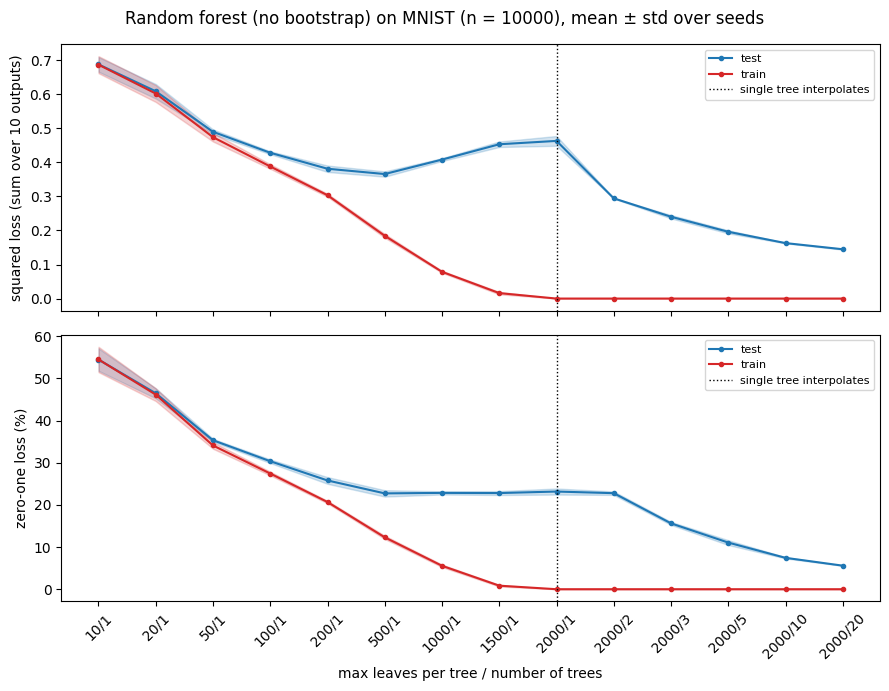

,Quantity,"Paper (≈, from figure)",Ours (mean ± std)
0,"Best single tree, test squared loss ÷ 10 (ours...",≈ 0.036,0.0366 ± 0.0008
1,"Single tree at max leaves (2000/1), test squar...",≈ 0.046,0.0463 ± 0.0014
2,"2000/20 trees, test squared loss ÷ 10",≈ 0.015,0.0145 ± 0.0001
3,"Best single tree, test error",≈ 22.5 %,22.72 ± 0.76 %
4,"Single tree at max leaves (2000/1), test error",≈ 23 %,23.16 ± 0.72 %
5,"2000/20 trees, test error",≈ 6 %,5.58 ± 0.04 %
6,Single tree at max leaves: train squared loss,0,0.0e+00


In [6]:
if "forest" in R:
    d = R["forest"]; n = int(d.n.iloc[0])
    order = [(L, 1) for L in sorted(d[d.trees == 1].leaves.unique())]
    Lmax = order[-1][0]
    order += [(Lmax, T) for T in sorted(d[(d.leaves == Lmax) & (d.trees > 1)].trees.unique())]
    g = d.groupby(["leaves", "trees"]); xs = np.arange(len(order))
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for ax, (te, tr, lab) in zip(axes, [("test_mse", "train_mse", "squared loss (sum over 10 outputs)"),
                                         ("test_err", "train_err", "zero-one loss (%)")]):
        for col, color, what in [(te, "C0", "test"), (tr, "C3", "train")]:
            m = g[col].mean().reindex(order).values; s = g[col].std().reindex(order).fillna(0).values
            ax.plot(xs, m, "o-", ms=3, color=color, label=what); ax.fill_between(xs, m - s, m + s, color=color, alpha=0.2)
        interp = next((i for i, k in enumerate(order) if g.train_mse.mean()[k] < 1e-8), None)
        if interp is not None:
            ax.axvline(interp, color="k", ls=":", lw=1, label="single tree interpolates")
        ax.set_ylabel(lab); ax.legend(fontsize=8)
    axes[1].set_xticks(xs, [f"{L}/{T}" for L, T in order], rotation=45)
    axes[1].set_xlabel("max leaves per tree / number of trees")
    fig.suptitle(f"Random forest (no bootstrap) on MNIST (n = {n}), mean ± std over seeds")
    fig.tight_layout(); save(fig, "fig_forest_mnist"); plt.show()

    single = d[d.trees == 1]
    best_L = single.groupby("leaves").test_mse.mean().idxmin()
    Tmax = d.trees.max()
    sel = lambda L, T, col: d[(d.leaves == L) & (d.trees == T)][col]
    rows = [[f"Best single tree, test squared loss ÷ 10 (ours {best_L} leaves)", "≈ 0.036", pm(sel(best_L, 1, "test_mse") / 10, 4)],
            [f"Single tree at max leaves ({Lmax}/1), test squared loss ÷ 10", "≈ 0.046", pm(sel(Lmax, 1, "test_mse") / 10, 4)],
            [f"{Lmax}/{Tmax} trees, test squared loss ÷ 10", "≈ 0.015", pm(sel(Lmax, Tmax, "test_mse") / 10, 4)],
            [f"Best single tree, test error", "≈ 22.5 %", pm(single.groupby('leaves').test_err.mean().pipe(lambda s: d[(d.trees == 1) & (d.leaves == s.idxmin())].test_err)) + " %"],
            [f"Single tree at max leaves ({Lmax}/1), test error", "≈ 23 %", pm(sel(Lmax, 1, "test_err")) + " %"],
            [f"{Lmax}/{Tmax} trees, test error", "≈ 6 %", pm(sel(Lmax, Tmax, "test_err")) + " %"],
            [f"Single tree at max leaves: train squared loss", "0", f"{sel(Lmax, 1, 'train_mse').mean():.1e}"]]
    save_table(rows, "table_forest", f"Random forest on MNIST, $n = 10^4$ (paper Fig.~5). Squared loss divided by 10 to match the paper's apparent per-output averaging.")

## 7. Overview figure for the slides: the same curve in three model families

Test zero-one error against model capacity, each relative to its own interpolation threshold (dotted line).

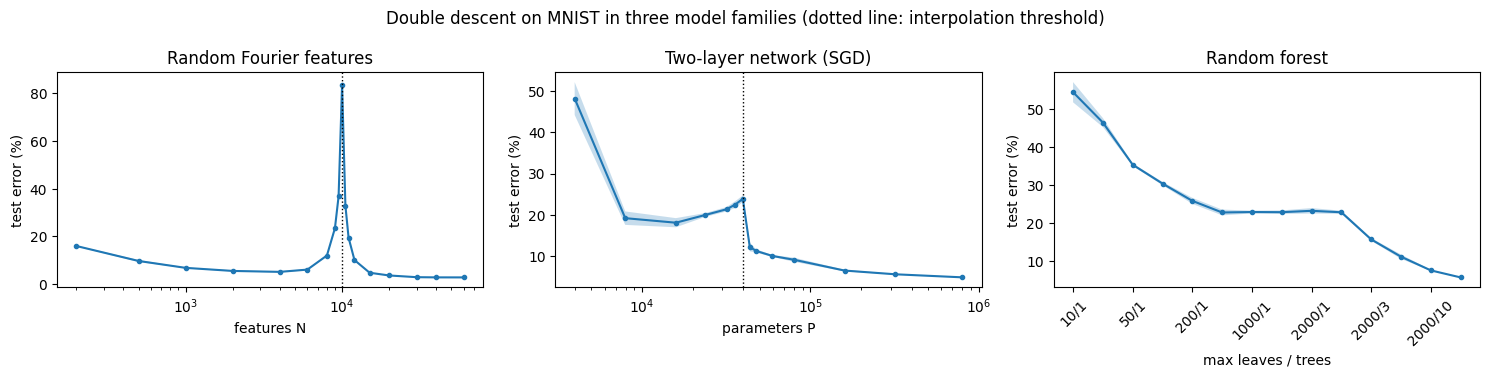

In [7]:
panels = []
if "rff" in R:
    d = R["rff"]; n = d.n.iloc[0]
    panels.append(("Random Fourier features", d.groupby("N").test_err, n, "features N", True))
if "mlp_reuse" in R:
    d = R["mlp_reuse"]; n = d.n.iloc[0]
    panels.append(("Two-layer network (SGD)", d.groupby("P").test_err, n * 10, "parameters P", True))
if "forest" in R:
    d = R["forest"]
    order = [(L, 1) for L in sorted(d[d.trees == 1].leaves.unique())]
    Lmax = order[-1][0]
    order += [(Lmax, T) for T in sorted(d[(d.leaves == Lmax) & (d.trees > 1)].trees.unique())]
    panels.append(("Random forest", (d.groupby(["leaves", "trees"]).test_err, order), None, "max leaves / trees", False))

if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (title, grp, thr, xlab, numeric) in zip(axes, panels):
        if numeric:
            m, s = grp.mean(), grp.std().fillna(0); x = m.index.values
            ax.plot(x, m.values, "o-", ms=3); ax.fill_between(x, (m - s).values, (m + s).values, alpha=0.25)
            ax.axvline(thr, color="k", ls=":", lw=1); ax.set_xscale("log")
        else:
            grp, order = grp
            m = grp.mean().reindex(order); s = grp.std().reindex(order).fillna(0); xs = np.arange(len(order))
            ax.plot(xs, m.values, "o-", ms=3); ax.fill_between(xs, (m - s).values, (m + s).values, alpha=0.25)
            ax.set_xticks(xs[::2], [f"{L}/{T}" for L, T in order][::2], rotation=45)
        ax.set_title(title); ax.set_xlabel(xlab); ax.set_ylabel("test error (%)")
    fig.suptitle("Double descent on MNIST in three model families (dotted line: interpolation threshold)")
    fig.tight_layout(); save(fig, "fig_overview"); plt.show()

## 8. Outputs
In `drive` mode everything is in `double-descent/figures/final/` on Drive. In `upload` mode a zip file is downloaded.

In [8]:
print("\n".join(sorted(os.listdir(OUT_DIR))))
if MODE == "upload":
    shutil.make_archive("/content/final_outputs", "zip", OUT_DIR)
    files.download("/content/final_outputs.zip")

fig_forest_mnist.pdf
fig_forest_mnist.png
fig_mlp_effective_params_mlp_noreuse.pdf
fig_mlp_effective_params_mlp_noreuse.png
fig_mlp_effective_params_mlp_reuse.pdf
fig_mlp_effective_params_mlp_reuse.png
fig_mlp_mnist.pdf
fig_mlp_mnist.png
fig_overview.pdf
fig_overview.png
fig_rff_mnist.pdf
fig_rff_mnist.png
table_forest.csv
table_forest.tex
table_mlp.csv
table_mlp.tex
table_relu_1d.csv
table_relu_1d.tex
table_rff.csv
table_rff.tex
